In [138]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

In [139]:
df = pd.read_csv(r"C:\Users\10880897\OneDrive - LTM\Desktop\LTM_PYTHON\practice\churn.csv")

In [140]:
#What to do after data comes

#df read
#EDA -> univariatw & bivariate analysis
#Data Cleaning
#Data Cleaning
df.shape

(10000, 13)

In [141]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), str(3)
memory usage: 1.2 MB


In [142]:
df.describe()

,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [143]:
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [144]:
#baseline is  -->
7963/10000

0.7963

In [145]:
x = df.iloc[:,2:-1] #values taken for x features to train on

In [146]:
x1 = pd.get_dummies(x, columns =["Geography","Gender"],drop_first =True) #removed the dummy categories - also known as hot encoding

In [ ]:
x1 #the logic for this is that even though you remove one conuntry or not it'lll still be the same search gpt if need to understand

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


In [147]:
y = df["Exited"] #data to predict from

In [148]:
from sklearn.model_selection import train_test_split

In [149]:
xtrain,xtest,ytrain,ytest = train_test_split(x1,y,test_size=0.20,random_state=12,stratify=y) #split the data is train 75 and learn 25

In [150]:
ytest.value_counts()

Exited
0    1593
1     407
Name: count, dtype: int64

In [151]:
ytrain.value_counts()

Exited
0    6370
1    1630
Name: count, dtype: int64

In [152]:
from sklearn.linear_model import LogisticRegression

In [153]:
lg = LogisticRegression(max_iter=22000)

In [154]:
model = lg.fit(xtrain,ytrain) #cant train as spain is in string so we need to encode the data, we've changed to c1 from x thats why it is working

In [155]:
xtrain.shape

(8000, 11)

In [156]:
#ROCR ==> Area under curve(AUC)

In [157]:
pred1=model.predict(xtest)

In [158]:
pd.crosstab(ytest,pred1) #this shows the confusion matrix to show the accuracy,precision matrix and recall

col_0,0,1
Exited,,
0,1525,68
1,330,77


In [159]:
#Accuracy 
#(tp+tn)/n #tp= true postitve , true negetive , n is number of test data

(1525+77)/2000

0.801

In [160]:
#Precision 
#(tp/tp+fp) #this mean how much actual correct did the model gave out of all the postivie data
77/(77+68)

0.5310344827586206

In [161]:
#Recall
#tp/(tp+fn)
77/(77+330)

0.1891891891891892

In [162]:
#Metric         Question
# Accuracy -  How often was my model correct overall?
# Precision - When model says YES, how often is it right?
# Recall   -  Of all the actual YES, how many did model find?

In [163]:
#Accuracy  = correct / everything
#         = (TP + TN) / Total

#Precision = TP / predicted positives
#          = TP / (TP + FP)

#Recall    = TP / actual positives
#          = TP / (TP + FN)

In [164]:
from sklearn.metrics import precision_score,accuracy_score,recall_score,classification_report

In [165]:
precision_score(ytest,pred1)

0.5310344827586206

In [166]:
recall_score(ytest,pred1)

0.1891891891891892

In [167]:
accuracy_score(ytest,pred1)

0.801

In [168]:
classification_report(ytest,pred1)

'              precision    recall  f1-score   support\n\n           0       0.82      0.96      0.88      1593\n           1       0.53      0.19      0.28       407\n\n    accuracy                           0.80      2000\n   macro avg       0.68      0.57      0.58      2000\nweighted avg       0.76      0.80      0.76      2000\n'

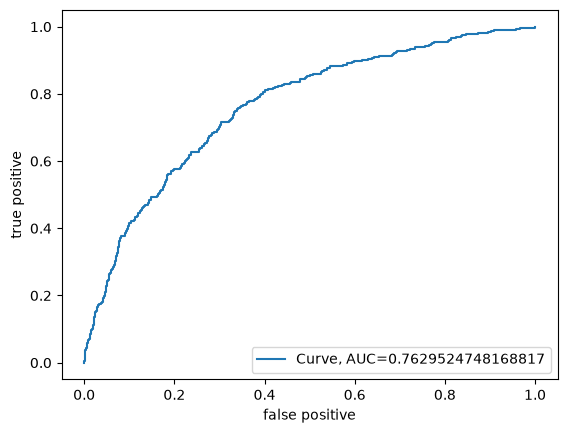

In [171]:
# ROCR/AUC to find the goodness of fit in the model
from sklearn import metrics
import matplotlib.pyplot as plt
y_pred_proba = model.predict_proba(xtest)[:,1]
fpr,tpr, _ = metrics.roc_curve(ytest,y_pred_proba)
AUC = metrics.roc_auc_score(ytest,y_pred_proba)
plt.plot(fpr,tpr,label="Curve, AUC="+str(AUC))
plt.legend(loc=4)
plt.xlabel('false positive')
plt.ylabel('true positive')
plt.show()

In [200]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_graphviz

dt = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=5,
    max_leaf_nodes=10,
    min_samples_split=5
)

model2 = dt.fit(xtrain, ytrain)

export_graphviz(
    model2,
    out_file="treeplot.dot",
    feature_names=x1.columns
)


In [201]:
pred2 = model2.predict(xtest)

In [202]:
pd.crosstab(ytest, pred2)

col_0,0,1
Exited,,
0,1529,64
1,233,174


In [203]:
accuracy_score(pred2,ytest)

0.8515

In [204]:
recall_score(pred2,ytest)

0.7310924369747899

In [205]:
precision_score(pred2,ytest)

0.4275184275184275

In [208]:
#SVM

In [209]:
#Support Vector Machine

In [210]:
#Feature Egineering

In [211]:
#Data transform/preprocessing

#label encodng,one hotencoding

#STANDARDISATION


In [216]:
#Class imbalance

In [217]:
from imblearn.over_sampling import SMOTE

In [218]:
s=SMOTE()

In [219]:
x

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10
...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77
9997,709,France,Female,36,7,0.00,1,0,1,42085.58
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52


In [ ]:
x_train_smote,y_train_smote = s.fit_resample(xtrain,ytrain)         #created sample test data 

In [221]:
y_train_smote.value_counts()

Exited
0    6370
1    6370
Name: count, dtype: int64

In [222]:
ytrain.value_counts()

Exited
0    6370
1    1630
Name: count, dtype: int64